# Predicting Alzheimer's Disease States from Single-Cell RNA-seq Data
**Author:** Tanvi Gambhir

### Project Overview
This notebook builds a machine learning pipeline to classify individual brain cells as either Healthy Control or Alzheimer's Disease (AD). By analyzing the transcriptomic profiles at the single-cell level, we can model the disease state and identify the specific genes that are driving neurodegeneration. 

The data used is from Mathys et al., 2019 (GEO Accession: GSE138852).

In [1]:
import pandas as pd
import scanpy as sc
import anndata as ad

### 1. Loading Data and Alignment
First, load the raw gene expression matrix and the corresponding cellular metadata files. Counts file shows the expression of genes within cells and the covariates file shows the metadata labels for cells. Since machine learning models require a specific orientation, I transposed the matrix so that the rows represent the individual cells and the columns represent the genes (features), and then packed them into an `AnnData` object for streamlined processing.

In [2]:
# index_col=0 so that the cell IDs become the row names
counts = pd.read_csv("/Users/tanvigambhir/Documents/neuro-ml/data/GSE138852_counts.csv", index_col=0)
covariates = pd.read_csv("/Users/tanvigambhir/Documents/neuro-ml/data/GSE138852_covariates.csv", index_col=0)

print("Counts shape:", counts.shape)
print("Covariates shape:", covariates.shape)

Counts shape: (10850, 13214)
Covariates shape: (13214, 5)


In [3]:
#flipping the matrix so cells are rows and genes are columns to match covariate matrix
if counts.shape[0] == 10850:
    counts = counts.T
print("New counts shape:", counts.shape)

# creating the AnnData object
adata = ad.AnnData(X=counts, obs=covariates)

# looking at available metadata 
print("\nMetadata Columns:")
print(adata.obs.columns.tolist())

New counts shape: (13214, 10850)

Metadata Columns:
['oupSample.batchCond', 'oupSample.cellType', 'oupSample.cellType_batchCond', 'oupSample.subclustID', 'oupSample.subclustCond']


In [4]:
# identifying the actual cell types in the data
print(adata.obs['oupSample.cellType'].value_counts())
#doublet is when machine counted two cells at once belnding their RNA sequences and unID is not identifiable cells (bad)
print("       ")
# identifying the disease labels
print(adata.obs['oupSample.batchCond'].value_counts())
#almost equal counts of AD and control cells which makes balancing model easier

oupSample.cellType
oligo      7432
astro      2171
OPC        1078
unID        925
neuron      656
mg          449
doublet     405
endo         98
Name: count, dtype: int64
       
oupSample.batchCond
AD    6673
ct    6541
Name: count, dtype: int64


### 2. Quality Control & Machine Learning Target Creation
Raw single-cell data contains technical noise so to ensure the model learns off real biology rather than experimental artifacts, I:
1. Removed Doublets & Unidentified Cells: Discarded droplets that accidentally captured multiple cells or failed classification.
2. Filtered Out Rare Genes: Dropped genes that are expressed in fewer than 10 cells to reduce dimensionality and noise.
3. Defined the Target: Mapped our disease states to binary labels (`AD` = 1, `Control` = 0) for the machine learning classifier.

In [5]:
print("quality control steps")
#removing cells we don't need
cellstoremove = ['doublet', 'unID']
adata = adata[~adata.obs['oupSample.cellType'].isin(cellstoremove)].copy()
print("\nnew size after dropping doublets and unIDs:", adata.shape)

#filtering out genes that are expressed in less than 10 cells -> these are just noise 
sc.pp.filter_genes(adata, min_cells=10)
print("new size after dropping the rare genes:", adata.shape)

# making AD = 1 ad control (ct) = 0 for model to learn
adata.obs['target'] = adata.obs['oupSample.batchCond'].map({'AD': 1, 'ct': 0})
print("\nNew ML target variable distribution:")
print(adata.obs['target'].value_counts())

#identifying how many cells were removed 
removed_cells = covariates[covariates['oupSample.cellType'].isin(['doublet', 'unID'])]
print(removed_cells['oupSample.cellType'].value_counts())
total_original_cells = len(covariates)
total_removed = len(removed_cells)
loss_percentage = (total_removed / total_original_cells) * 100
print(f"\ntotal cells removed: {total_removed}")
print(f"percentage of dataset lost: {loss_percentage:.2f}%")

quality control steps

new size after dropping doublets and unIDs: (11884, 10850)
new size after dropping the rare genes: (11884, 10848)

New ML target variable distribution:
target
0    6120
1    5764
Name: count, dtype: int64
oupSample.cellType
unID       925
doublet    405
Name: count, dtype: int64

total cells removed: 1330
percentage of dataset lost: 10.07%


### 3. Normalization & Dimensionality Reduction (UMAP)
Before feeding the data into a model, I had to normalize the gene counts to account for differences in sequencing depth across cells. 
I log-transformed the data to isolate the top 2,000 highly variable genes in order to focus on the most biologically informative features. 
Finally, I compressed these high-dimensional profiles using PCA and UMAP to visually confirm that the cell types and disease states form distinct, learnable clusters.

normalizing the data

the most informative genes


/opt/anaconda3/lib/python3.13/functools.py:934: UserWarning: Received a view of an AnnData. Making a copy.
  return dispatch(args[0].__class__)(*args, **kw)
OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


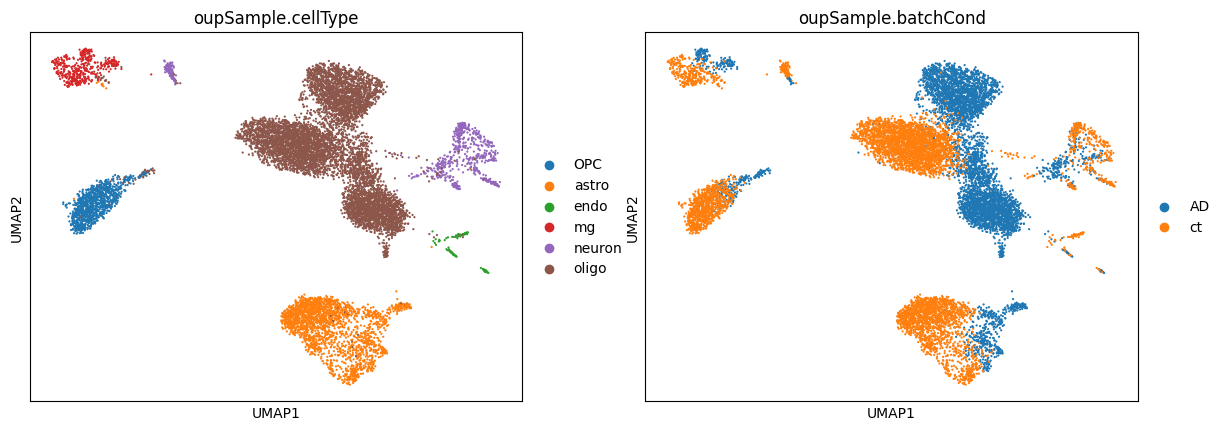

In [6]:
print("normalizing the data")
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata) # log transform to handle extreme outliers

print("\nthe most informative genes")
# only want to train the model on genes that actually change between cells
sc.pp.highly_variable_genes(adata, n_top_genes=2000)
adata = adata[:, adata.var.highly_variable] #keeping only the highly variable genes

#standardizing the data 
sc.pp.scale(adata, max_value=10)

#compressing the dimensions
sc.tl.pca(adata, svd_solver='arpack')
sc.pp.neighbors(adata, n_neighbors=10, n_pcs=40)
sc.tl.umap(adata)

#plotting by cell type and then disease state
sc.pl.umap(adata, color=['oupSample.cellType', 'oupSample.batchCond'])

In [7]:
#cellType graph shows distinct clusters for each cell type 
#batchCond graph shows that Alzheimer's doesn't completely change a cell's identity, but the disease does drastically alter its internal gene expression state


### 4. Machine Learning Classification (Random Forest Classifier)
With the biology cleaned and normalized, I built a Random Forest Classifier to distinguish between AD and Healthy Control cells. I split the data (80% training, 20% testing) to ensure that the model is evaluated on cells it has never seen before, proving its ability to generalize.

In [9]:
print("Developing the model. Using a random forest classifier to see which genes it uses to make its decisions.")
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# extracting the features (X) and target labels (y)
X = adata.X
y = adata.obs['target'].values

# splitting data into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# initializing the random forest model
# creating 100 decision trees that will vote on whether a cell is AD or Control
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)

# training the model
rf_model.fit(X_train, y_train)

# making predictions on our testing data
predictions = rf_model.predict(X_test)

# evaluating how well model learned
accuracy = accuracy_score(y_test, predictions)
print(f"Model Accuracy on unseen cells: {accuracy * 100:.2f}%")

Developing the model. Using a random forest classifier to see which genes it uses to make its decisions.
Model Accuracy on unseen cells: 94.91%


### 5. Biological Interpretation (Feature Extraction)
Since I used a Random Forest Classifier, I can extract the Feature Importances to see exactly which genes the model relied on to identify Alzheimer's cells. 

By isolating the top 20 genes, I cross-referenced the mathematical model with known neurodegenerative literature to identify potential disease drivers and therapeutic targets. The Random Forest classifier identified several key genes that perfectly align with documented neurodegenerative pathology:

* LINGO1 (Top Predictor): A known negative regulator of myelination and neuronal survival. Its emergence as the top feature highlights severe myelin breakdown and points to a highly relevant therapeutic target for neural repair.
* NEAT1 & LINC00486: Long non-coding RNAs strongly associated with cellular stress responses and paraspeckle formation. Their high importance indicates the model successfully detected the transcriptomic panic mode of diseased cells.
* HSPA1A: A major heat shock protein. Its presence reflects the cellular stress response attempting to clear misfolded protein aggregates, such as amyloid-beta and tau plaques characteristic of AD.
* XIST: The gene responsible for X-chromosome inactivation. Its predictive weight suggests the model captured critical sex-specific differences in how AD pathology manifests at the cellular level.

Summary: This pipeline successfully moved from raw, noisy single-cell RNA-seq data to a highly accurate predictive model, ultimately identifying biologically actionable drug targets and disease markers.

Visualizing Feature Importance


/var/folders/mj/1z94nrj90vxcwclytrnchs5c0000gn/T/ipykernel_11415/3953541200.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Gene', data=top_20_genes, palette='magma')


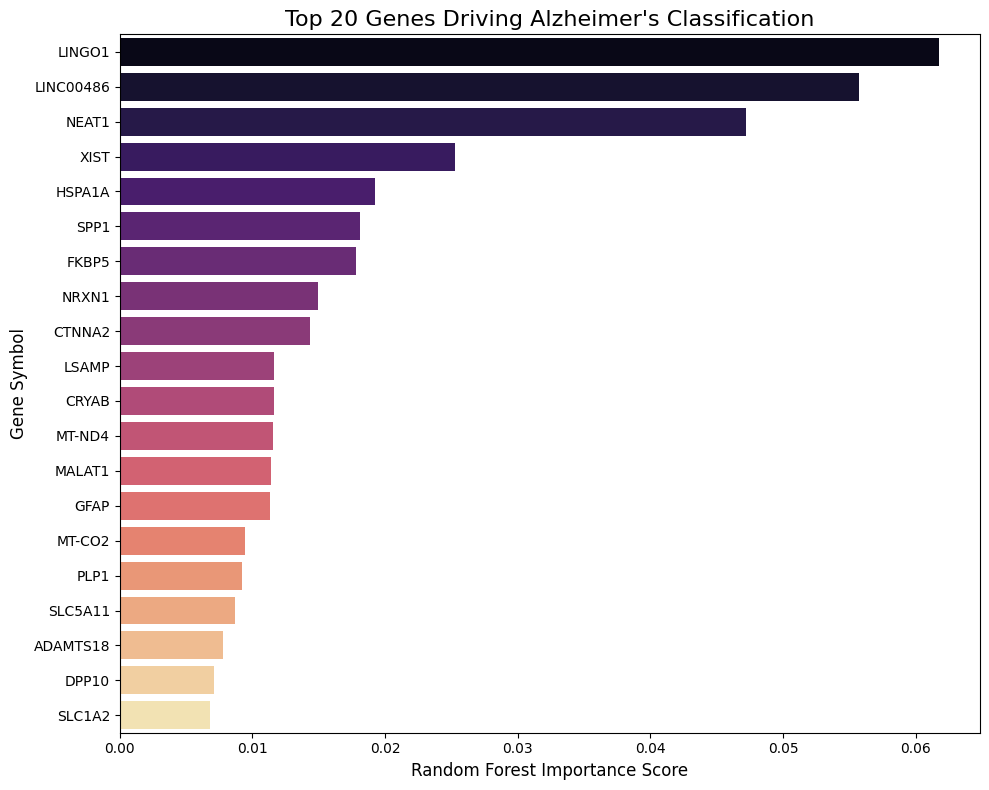

Top 5 Genes from Data
     Gene  Importance
   LINGO1    0.061759
LINC00486    0.055750
    NEAT1    0.047232
     XIST    0.025296
   HSPA1A    0.019234


In [11]:
print("Visualizing Feature Importance")
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

importances = rf_model.feature_importances_
gene_names = adata.var_names
gene_importance_df = pd.DataFrame({
    'Gene': gene_names,
    'Importance': importances
})
top_20_genes = gene_importance_df.sort_values(by='Importance', ascending=False).head(20)

plt.figure(figsize=(10, 8))
sns.barplot(x='Importance', y='Gene', data=top_20_genes, palette='magma')
plt.title("Top 20 Genes Driving Alzheimer's Classification", fontsize=16)
plt.xlabel("Random Forest Importance Score", fontsize=12)
plt.ylabel("Gene Symbol", fontsize=12)
plt.tight_layout()
plt.show()

print("Top 5 Genes from Data")
print(top_20_genes.head(5).to_string(index=False))